In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cf
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.transforms as mtransforms
import matplotlib.ticker as ticker

from dask.diagnostics import ProgressBar

In [2]:
# gridded radiation data
path_rad = '/jetfs/scratch/psplechtna/thesisdata/radfluxes/z/2024/'
filename_rad = 'highres_2024*.nc'

In [3]:
rad_grid = xr.open_mfdataset(
    path_rad + filename_rad,
    combine='nested',
    concat_dim='valid_time',
    chunks={'valid_time': 1})

times = rad_grid.indexes["valid_time"]

# Keep the first occurrence of each timestamp
_, unique_indices = np.unique(times, return_index=True)

# Preserve the original order of the retained timestamps
unique_indices = np.sort(unique_indices)

rad_grid = rad_grid.isel(valid_time=unique_indices)

In [4]:
rad_grid

<xarray.Dataset> Size: 171GB
Dimensions:     (valid_time: 1608, height: 51, latitude: 181, longitude: 720)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 13kB 2024-07-01 ... 2024-09-05T23...
  * height      (height) int64 408B 20 50 100 200 ... 11000 12000 15000 20000
  * latitude    (latitude) float64 1kB 90.0 89.5 89.0 88.5 ... 1.5 1.0 0.5 0.0
  * longitude   (longitude) float64 6kB -179.5 -179.0 -178.5 ... 179.5 180.0
Data variables:
    avg_ttswr   (valid_time, height, latitude, longitude) float64 85GB dask.array<chunksize=(1, 51, 181, 720), meta=np.ndarray>
    avg_ttlwr   (valid_time, height, latitude, longitude) float64 85GB dask.array<chunksize=(1, 51, 181, 720), meta=np.ndarray>
Attributes:
    description:  Weighted mean variables

In [5]:
lw = rad_grid.avg_ttlwr
sw = rad_grid.avg_ttswr

In [6]:
lw_inst = lw.isel(valid_time=124).sel(height=1400)
sw_inst = sw.isel(valid_time=124).sel(height=1400)

In [7]:
cp=1005

In [8]:
with ProgressBar():
    lw_inst=(lw_inst*3600).load()
    sw_inst=(sw_inst*3600).load()

[########################################] | 100% Completed | 104.25 ms
[########################################] | 100% Completed | 127.46 ms


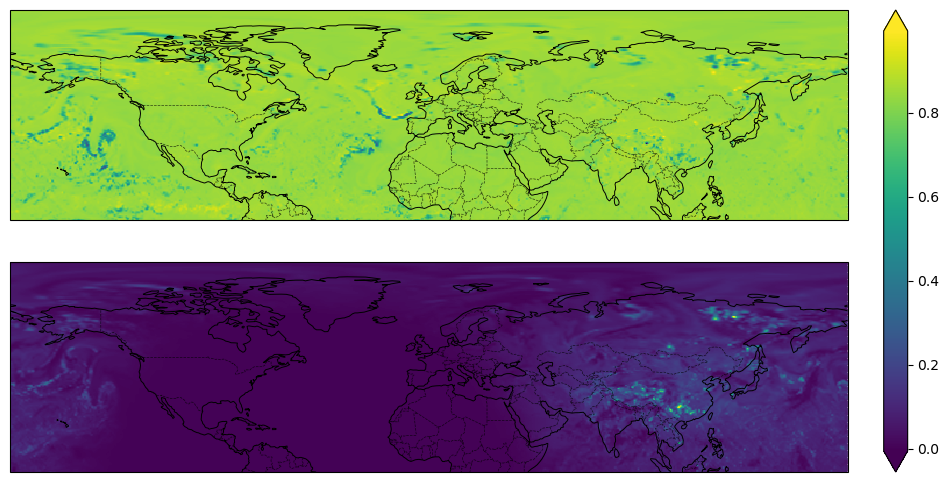

In [9]:
fig, ax = plt.subplots(2,1, figsize=(12,6), subplot_kw={'projection': ccrs.PlateCarree()})

contour=ax[0].pcolormesh(lw_inst.longitude, lw_inst.latitude, lw_inst)

contour=ax[1].pcolormesh(sw_inst.longitude, sw_inst.latitude, sw_inst)

for axs in ax.flatten():
    axs.grid()
    axs.add_feature(cf.COASTLINE, linewidth=0.7)
    axs.add_feature(cf.BORDERS, linewidth=0.5, linestyle='--', alpha=0.7)

all_axes = ax[:]
bbox = mtransforms.Bbox.union([ax.get_position() for ax in all_axes])
cbar_width = 0.02
cbar_pad = 0.01
cax = fig.add_axes([
    bbox.x1 + cbar_pad + cbar_width,                       
    bbox.y0,
    cbar_width,
    bbox.height,          
])
cb = fig.colorbar(contour, orientation='vertical', cax=cax,
                 extend='both', shrink=0.8)      # arrows for out-of-range values


In [10]:
lw_vert = lw.sel(latitude=slice(90,20)).mean(dim=['valid_time', 'latitude', 'longitude'])
sw_vert = sw.sel(latitude=slice(90,20)).mean(dim=['valid_time', 'latitude', 'longitude'])

In [11]:
with ProgressBar():
    lw_vert = (lw_vert*3600*24).load()
    sw_vert = (sw_vert*3600*24).load()

[########################################] | 100% Completed | 138.75 s
[########################################] | 100% Completed | 130.32 s


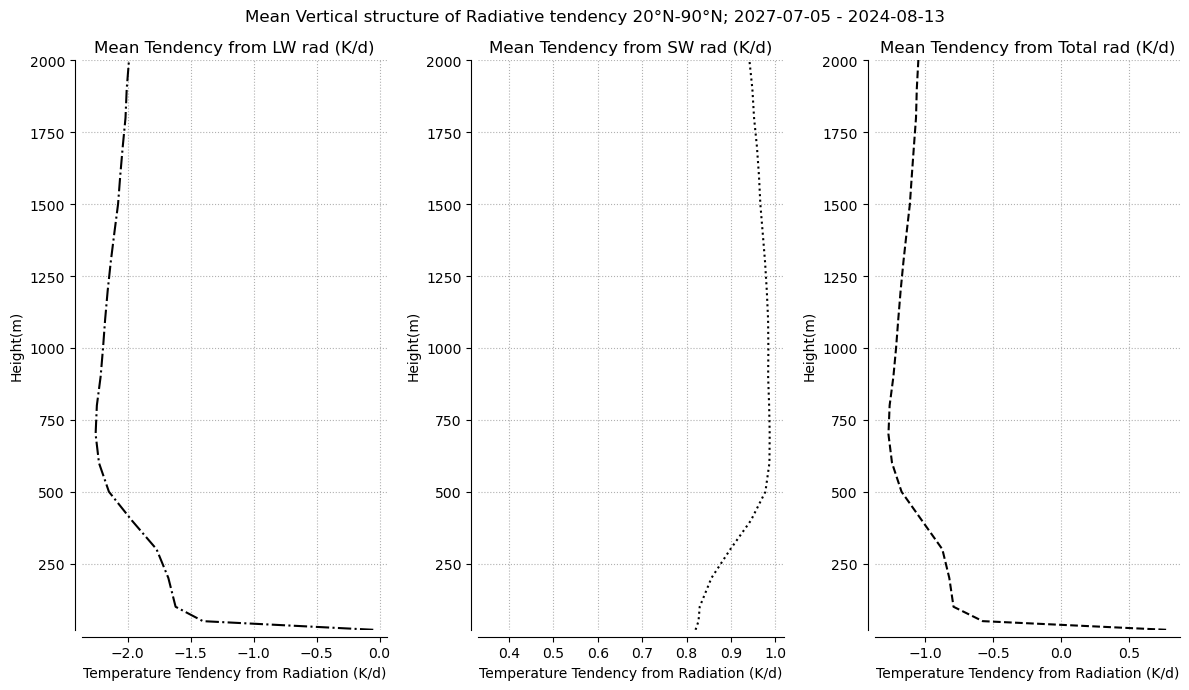

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(12,7))
ax[0].plot(lw_vert, lw_vert.height, '-.k')
ax[0].set_title('Mean Tendency from LW rad (K/d)')
ax[1].plot(sw_vert, sw_vert.height, ':k')
ax[1].set_title('Mean Tendency from SW rad (K/d)')
ax[2].plot(sw_vert+lw_vert, sw_vert.height, '--k')
ax[2].set_title('Mean Tendency from Total rad (K/d)')

fig.suptitle('Mean Vertical structure of Radiative tendency 20°N-90°N; 2027-07-05 - 2024-08-13')
for axs in ax.flatten():
    axs.grid(linestyle=':')
    for spine in ['top', 'right']:
        axs.spines[spine].set_visible(False)
    spine_offset=5
    axs.spines.left.set_position(('outward', spine_offset))
    axs.spines.bottom.set_position(('outward', spine_offset))
    axs.set_ylim(20,2000)
    axs.set_xlabel('Temperature Tendency from Radiation (K/d)')
    axs.set_ylabel('Height(m)')
    #axs.set_xlim(290000,350000)
fig.tight_layout()